# LSTM Mini Demo: Karakter Düzeyinde Dil Modeli
**BİL 822 · Büyük Dil Modelleri ve Uygulamaları**

**Hazırlayanlar:** Öznur YAKUT & Büşra KURUN

Bu not defteri küçük bir LSTM'i bir metin üzerinde eğitir ve eğitim ilerledikçe modelin ürettiği metnin nasıl değiştiğini gösterir.

**Nasıl çalıştırılır:** Colab'da *Çalışma zamanı → Tümünü çalıştır*; kendi bilgisayarınızda Jupyter'de *Run All*. İlk hücre PyTorch'u gerekirse kendisi kurar. CPU yeterlidir (yaklaşık 1–2 dakika).

**Ne göreceğiz?**
1. Başta model rastgele harfler üretir.
2. Birkaç düzine adım sonra hece ve kelime benzeri diziler çıkar.
3. Eğitim bittiğinde model, gördüğü metnin diline benzer cümleler kurar.

In [1]:
# PyTorch yüklü değilse otomatik kurar (Colab'da zaten yüklüdür, bu hücre hemen biter).
try:
    import torch
    print("PyTorch hazır:", torch.__version__)
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "torch"])
    import torch
    print("PyTorch kuruldu:", torch.__version__)

PyTorch hazır: 2.11.0+cpu


## 1. Veri
Varsayılan olarak kısa bir Türkçe metin kullanılır. Daha iyi sonuç için kendi metin dosyanızı yükleyebilirsiniz (aşağıdaki hücreyi `True` yapın).

In [2]:
import torch
import torch.nn as nn

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"

KENDI_METNIM = False   # True yaparsanız bir .txt dosyası yüklemeniz istenir

VARSAYILAN_METIN = (
    "Uzun kısa süreli bellek ağları, tekrarlayan sinir ağlarının uzun vadeli "
    "bağımlılıkları öğrenememesi sorununa çözüm olarak geliştirildi. "
    "Bir LSTM hücresi, bilgiyi ne zaman yazacağına, ne kadar tutacağına ve ne "
    "zaman okuyacağına kapılar aracılığıyla karar verir. Unutma kapısı eski "
    "bilgiyi siler, giriş kapısı yeni bilgiyi yazar, çıkış kapısı ise bellekten "
    "o an gereken bilgiyi okur. Hücre durumu, zaman adımları boyunca neredeyse "
    "dokunulmadan akan bir bellek bandı gibi çalışır. Bu sayede öğrenme sinyali "
    "uzun mesafeler boyunca kaybolmadan taşınabilir. "
) * 40

if KENDI_METNIM:
    from google.colab import files
    yuklenen = files.upload()
    text = open(next(iter(yuklenen)), encoding="utf-8").read()
else:
    text = VARSAYILAN_METIN

chars = sorted(set(text)) # metni karakterlere ayırma
stoi = {c: i for i, c in enumerate(chars)} # Her karaktere bir sayı verme
itos = {i: c for c, i in stoi.items()} #Sayıyı yeniden karaktere dönüştürme
data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
print(f"Metin: {len(text):,} karakter | Sözlük: {len(chars)} karakter | Cihaz: {device}")

Metin: 22,080 karakter | Sözlük: 38 karakter | Cihaz: cpu


## 2. Eğitim örnekleri
Model her karakter için **bir sonraki karakteri** tahmin etmeyi öğrenir. Hedef, girdinin bir karakter sağa kaydırılmış hâlidir.

In [3]:
SEQ_LEN = 100 #karakter sayısı
BATCH = 32 # örnek sayısı

def get_batch():
    ix = torch.randint(len(data) - SEQ_LEN - 1, (BATCH,))
    x = torch.stack([data[i : i + SEQ_LEN] for i in ix])
    y = torch.stack([data[i + 1 : i + SEQ_LEN + 1] for i in ix])
    return x.to(device), y.to(device)

x, y = get_batch()
print("Girdi :", "".join(itos[i.item()] for i in x[0][:40]))
print("Hedef :", "".join(itos[i.item()] for i in y[0][:40]))

Girdi :  uzun mesafeler boyunca kaybolmadan taşı
Hedef : uzun mesafeler boyunca kaybolmadan taşın


## 3. Model
Üç parça: **Embedding** (karakter → vektör), **2 katmanlı LSTM** (hafızalı okuma), **Linear** (sonraki karakter olasılıkları).

Küçük bir ayrıntı: unutma kapısının başlangıç değerini "açık" yapıyoruz ki model baştan hafızayı korumayı denesin.

In [4]:
# Karakterlerden öğrenebilen sinir ağı modelini tanımlıyor.
'''
vocab	38	Sözlükteki benzersiz karakter sayısı
emb	64	Her karakterin vektör boyutu
hid	256	LSTM'nin gizli durum boyutu
'''

class CharLSTM(nn.Module):
    def __init__(self, vocab, emb=64, hid=256):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb)
        self.lstm = nn.LSTM(emb, hid, num_layers=2, batch_first=True, dropout=0.2)
        self.out = nn.Linear(hid, vocab)
        for name, p in self.lstm.named_parameters():
            if "bias" in name:
                n = p.size(0)
                with torch.no_grad():
                    p[n // 4 : n // 2].fill_(1.0)   # unutma kapısı açık başlasın

    def forward(self, x, state=None):
        h, state = self.lstm(self.emb(x), state)
        return self.out(h), state

#Modelin öğrendiği (veya henüz öğrenmediği) bilgilerle sıradaki karakterleri üretmesini sağlıyor.
@torch.no_grad()
def generate(model, start="Bir LSTM ", length=150, temperature=0.8):
    model.eval()
    start = "".join(c for c in start if c in stoi) or chars[0]
    x = torch.tensor([[stoi[c] for c in start]], device=device)
    logits, state = model(x)
    out = start
    for _ in range(length):
        probs = torch.softmax(logits[:, -1] / temperature, dim=-1)
        nxt = torch.multinomial(probs, 1)
        out += itos[nxt.item()]
        logits, state = model(nxt, state)   # hafıza bir sonraki adıma taşınır
    model.train()
    return out

model = CharLSTM(len(chars)).to(device)
print(f"Parametre sayısı: {sum(p.numel() for p in model.parameters()):,}")
print("\nEğitimden ÖNCE üretilen metin:\n")
print(generate(model))

Parametre sayısı: 868,262

Eğitimden ÖNCE üretilen metin:

Bir LSTM oiStotB.sBikHkgmkntdugUuHtuotşzvv.şıe,iLspmMzpmsLüT,SbfüykfSuuvcz.LnvdgıkLeğhadTogoMBçı,hUhevBoMTfğtTtşğlıökprLSopdpççmUHtşsfc,LpUSiımHcntUbMoökzfzUfS


## 4. Eğitim ve canlı üretim
Belirli adımlarda modelden örnek metin isteriz. Çıktının nasıl düzeldiğine dikkat edin.

In [5]:
opt = torch.optim.Adam(model.parameters(), lr=3e-3)
loss_fn = nn.CrossEntropyLoss()
STEPS = 1000
GOSTER = {25, 50, 100, 200, 500, 1000}

for step in range(1, STEPS + 1):
    x, y = get_batch()
    logits, _ = model(x)
    loss = loss_fn(logits.reshape(-1, len(chars)), y.reshape(-1))
    opt.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # aşırı büyük güncellemeleri sınırla
    opt.step()

    if step in GOSTER:
        print(f"\n--- adım {step:4d} | hata {loss.item():.3f} ---")
        print(generate(model))


--- adım   25 | hata 2.592 ---
Bir LSTM gBic ugı an, zdlebile yakıar ngi  üga üdaları ,leolna iir eseeln euçener ösi beley f aee gari ki.a iısi tzoerleyi e bili ll.car nağa.a cla bağııı lark

--- adım   50 | hata 1.461 ---
Bir LSTM Uüccar bele bek galağlağınıya karip, karı geukar tenemi yenla, biyiy rür Lucun acara kapını ounma okunad kelen tayakralırızi varer nenuc sa mesi bile 

--- adım  100 | hata 0.196 ---
Bir LSTM hücresi, bilgiyi ne zaman yazacağına, ne kadar tutacağına ve ne zaman okuyacağına kapılar aracılığıyla karar verir. But madan arıde bir zelamı sanele 

--- adım  200 | hata 0.065 ---
Bir LSTM hücresi, bilgiyi ne zaman yazacağına, ne kadar tutacağına ve ne zaman okuyacağına kapılar aracılığıyla karar verir. Unutma kapısı eski bilgiyi siler, 

--- adım  500 | hata 0.041 ---
Bir LSTM hücresi, bilgiyi ne zaman yazacağına, ne kadar tutacağına ve ne zaman okuyacağına kapılar aracılığıyla karar verir. Unutma kapısı eski bilgiyi siler, 

--- adım 1000 | hata 0.036 ---
Bir LSTM

## 5. Tartışma notları
- **Neden ilk adımlarda anlamsız?** Model henüz hangi karakterin hangisinden sonra geldiğini bilmiyor.
- **Neden sonunda metni neredeyse aynen üretiyor?** Eğitim metni çok kısa; model genelleştirmek yerine **ezberledi**. Daha büyük bir metinle denerseniz (yukarıda `KENDI_METNIM = True`) model gerçekten yeni cümleler kurar.
- **LSTM'in rolü:** Bir kelimenin ortasındayken önceki harfleri, cümle ortasında önceki kelimeleri hatırlamak için hafıza şeridini kullanır.
- **Sınırlılık:** Çok uzun bağlamlarda ve büyük ölçekte Transformer modellerine göre zayıf kalır; sunumun karşılaştırma slaytında anlattığımız gibi.

In [6]:

test_metni = """
Yapay zekâ, bilgisayarların verilerden öğrenmesini sağlar.
Derin öğrenme, sinir ağlarını kullanarak karmaşık örüntüleri
öğrenebilir. Bazı modeller metin üretmek için eğitilir.
"""

test_data = torch.tensor(
    [stoi[c] for c in test_metni if c in stoi],
    dtype=torch.long,
    device=device
)

with torch.no_grad():
    logits, _ = model(test_data[:-1].unsqueeze(0))
    test_loss = loss_fn(
        logits.reshape(-1, len(chars)),
        test_data[1:].unsqueeze(0).reshape(-1)
    )

print("Test metni:", test_metni)
print("Test hatası:", round(test_loss.item(), 3))
print("\nModelin ürettiği metin:")
print(generate(model, start="Yapay zekâ ", length=150))


Test metni: 
Yapay zekâ, bilgisayarların verilerden öğrenmesini sağlar.
Derin öğrenme, sinir ağlarını kullanarak karmaşık örüntüleri
öğrenebilir. Bazı modeller metin üretmek için eğitilir.

Test hatası: 4.538

Modelin ürettiği metin:
apay zek ağları, tekrarlayan sinir ağlarının uzun vadeli bağımlılıkları öğrenememesi sorununa çözüm olarak geliştirildi. Bir LSTM hücresi, bilgiyi ne zaman yaz


In [7]:

bilinmeyenler = sorted(set(test_metni) - set(stoi.keys()))

print("Sözlükteki karakter sayısı:", len(chars))
print("Testte bulunup sözlükte olmayan karakterler:", bilinmeyenler)


Sözlükteki karakter sayısı: 38
Testte bulunup sözlükte olmayan karakterler: ['\n', 'D', 'Y', 'â']


# Deney 2: Daha Geniş Bir Metinle LSTM Eğitimi

Bu deneyde, önceki deneyimizden farklı olarak çeşitli konuları içeren daha kapsamlı bir metin kullanacağız.

Amacımız:
- Daha çeşitli metinlerle eğitilen LSTM'nin nasıl metin ürettiğini gözlemlemek.
- Eğitim hatası ile doğrulama hatasını karşılaştırmak.
- Modelin daha önce görmediği bir metindeki karakterleri ne kadar iyi tahmin ettiğini test etmek.

Bu deneyde yeni bir karakter sözlüğü ve yeni bir LSTM modeli oluşturacağız.

In [8]:

wide_corpus = """
Yapay Zekâ ve Öğrenme

Yapay zekâ, bilgisayarların normalde insan zekâsı gerektiren
bazı görevleri yerine getirmesini sağlayan yöntemlerin genel
adıdır. Bu görevler arasında dili anlamak, görüntüleri tanımak,
tahmin yapmak ve karar vermeye yardımcı olmak bulunur.
Makine öğrenmesi, bilgisayarların örneklerden yararlanarak
örüntüler öğrenmesini sağlar. Model, eğitim sırasında verileri
inceler ve tahminlerinin hatalarını azaltmaya çalışır.
Ancak bir modelin eğitim verisinde başarılı olması, yeni
verilerde de aynı başarıyı göstereceği anlamına gelmez.

Derin öğrenme, çok katmanlı yapay sinir ağlarından yararlanır.
Her katman, verinin farklı özelliklerini öğrenebilir.
Örneğin bir görüntü modelinin ilk katmanları basit çizgileri
ve kenarları, sonraki katmanları ise daha karmaşık şekilleri
tanıyabilir. Metin işleyen modeller ise kelimeler veya
karakterler arasındaki ilişkileri öğrenmeye çalışır.
Tekrarlayan sinir ağları, sıralı verilerle çalışmak üzere
geliştirilmiştir. LSTM mimarisi, bilgiyi zaman adımları
boyunca taşımaya yardımcı olan bir bellek durumu kullanır.
Giriş, unutma ve çıkış kapıları, bu belleğin nasıl
güncelleneceğini belirler. Böylece önceki bilgiler ile
yeni bilgiler arasında bir denge kurulabilir.

Bilim ve Doğa

Doğa, birbirleriyle sürekli etkileşim hâlinde olan canlıları,
iklimi, suyu, toprağı ve havayı kapsayan büyük bir sistemdir.
Bir ormanda ağaçlar güneş ışığından yararlanarak büyür.
Bitkiler, fotosentez sırasında ışık enerjisini kimyasal enerjiye
dönüştürür. Hayvanlar besin bulmak, korunmak ve çoğalmak için
çevreleriyle etkileşim kurar. Bir türün sayısındaki değişim,
aynı ortamda yaşayan başka türleri de etkileyebilir.
Bu nedenle ekosistemlerdeki denge, birçok farklı etkene bağlıdır.

Su, yaşam için vazgeçilmez kaynaklardan biridir. Güneşin
ısısı denizlerdeki ve göllerdeki suyun bir bölümünü buharlaştırır.
Su buharı atmosferde yükselir, soğur ve küçük damlacıklara
dönüşerek bulutları oluşturabilir. Yağışlarla yeryüzüne dönen
su, nehirlere, göllere ve yer altına ulaşır. Bu döngü doğadaki
suyun sürekli hareket etmesini sağlar. İklim değişikliği,
şehirleşme ve kaynakların bilinçsiz kullanılması bu doğal
süreçleri etkileyebilir. Temiz suyu korumak, atıkları azaltmak
ve doğal alanları yaşatmak bu yüzden önemlidir.

İnsan ve Öğrenme

İnsanlar yeni bilgiler öğrenirken gözlem yapar, soru sorar,
denemeler gerçekleştirir ve sonuçları değerlendirir.
Bir konuyu yalnızca okumak bazen yeterli olmaz. Bilgiyi
uygulamak, hata yapmak ve hatanın nedenini anlamak öğrenmeyi
güçlendirebilir. Düzenli tekrar, bilgilerin hatırlanmasına
yardım eder. Bununla birlikte her şeyi ezberlemek, bir konuyu
gerçekten anlamakla aynı şey değildir. Bir öğrenci öğrendiği
bilgiyi yeni bir problemde kullanabiliyorsa konuyu daha derin
anlamış olabilir.

Bilgisayar programlamayı öğrenirken de benzer bir süreç işler.
Önce bir problemin ne istediği anlaşılır. Ardından çözüm
küçük adımlara ayrılır ve bu adımlar bir programla ifade edilir.
Program beklenen sonucu vermediğinde hata mesajları incelenir.
Kodun hangi bölümünün yanlış çalıştığı araştırılır ve gerekli
düzeltmeler yapılır. Deneme ve hata ayıklama, yazılım
geliştirmenin doğal parçalarıdır. Büyük bir projeyi küçük
bölümlere ayırmak, sorunları daha kolay bulmayı sağlar.

Teknoloji ve Günlük Yaşam

İnternet, insanların bilgiye ulaşma ve birbirleriyle iletişim
kurma biçimlerini değiştirmiştir. Bir öğrenci farklı ülkelerdeki
kaynakları inceleyebilir, çevrim içi derslere katılabilir ve
uzak bir ekipteki kişilerle birlikte çalışabilir. Öte yandan
internetteki her bilginin doğru olduğu varsayılmamalıdır.
Kaynağın güvenilirliği kontrol edilmeli, farklı açıklamalar
karşılaştırılmalı ve kişisel bilgiler korunmalıdır.

Veri bilimi, büyük miktardaki veriden anlamlı sonuçlar
çıkarmaya çalışır. Bir mağaza geçmiş satış kayıtlarını
inceleyerek hangi ürünlere daha fazla ihtiyaç duyulacağını
tahmin edebilir. Bir hastane, hizmet süreçlerini değerlendirmek
için randevu ve işlem verilerinden yararlanabilir. Bir ulaşım
sistemi, trafik yoğunluğunu analiz ederek daha uygun güzergâhlar
önerebilir. Bu örneklerde verinin kalitesi ve doğru yorumlanması
sonuçların güvenilirliğini etkiler. Yanlış veya eksik veri,
yanlış kararların alınmasına neden olabilir.

Gelecek İçin Sorumluluk

Yeni teknolojiler pek çok fırsat sunarken bazı sorumlulukları
da beraberinde getirir. Yapay zekâ sistemleri hatalı sonuçlar
üretebilir ve eğitim verilerindeki önyargıları yansıtabilir.
Bu nedenle modellerin nasıl değerlendirildiği, hangi verilerle
eğitildiği ve hangi durumlarda başarısız olduğu incelenmelidir.
Özellikle sağlık, eğitim ve finans gibi alanlarda kararların
etkileri dikkatle ele alınmalıdır.

Başarılı bir öğrenme süreci yalnızca yüksek bir puan elde
etmekten ibaret değildir. Modelin hangi örneklerde başarılı
olduğu, nerelerde hata yaptığı ve yeni durumlara nasıl tepki
verdiği de önemlidir. Bir sistemi değerlendirirken hem güçlü
yönlerini hem de sınırlamalarını anlamaya çalışmalıyız.
Bilimsel yaklaşım, varsayımları sınamayı, kanıtları incelemeyi
ve yeni sonuçlara göre düşüncelerimizi güncellemeyi gerektirir.
"""
print("Eğitim metninin karakter sayısı:", len(wide_corpus))


Eğitim metninin karakter sayısı: 5093


## Veriyi Hazırlama

Model metni doğrudan okuyamaz. Önce metindeki karakterleri sayısal değerlere dönüştüreceğiz.

Ardından metni iki parçaya ayıracağız:
- **Eğitim verisi:** Modelin öğrenmek için kullanacağı bölüm.
- **Doğrulama verisi:** Eğitim sırasında modelin daha önce öğrenmediği bölümdeki başarısını izlemek için kullanacağımız kısım.

Karakter sözlüğünü, eğitim ve doğrulama metnindeki karakterleri kapsayacak şekilde oluşturacağız. Böylece doğrulama verisindeki karakterler sözlükte olmadığı için silinmeyecek.

In [9]:

# Eğitim metninin son %10'unu doğrulama için ayırıyoruz.
split_at = int(len(wide_corpus) * 0.90)

wide_train_text = wide_corpus[:split_at]
wide_val_text = wide_corpus[split_at:]

# Her iki bölümdeki karakterleri kapsayan sözlük.
wide_chars = sorted(set(wide_corpus))

wide_stoi = {c: i for i, c in enumerate(wide_chars)}
wide_itos = {i: c for c, i in wide_stoi.items()}

wide_train_data = torch.tensor(
    [wide_stoi[c] for c in wide_train_text],
    dtype=torch.long
)

wide_val_data = torch.tensor(
    [wide_stoi[c] for c in wide_val_text],
    dtype=torch.long
)

print("Toplam karakter:", len(wide_corpus))
print("Eğitim karakteri:", len(wide_train_text))
print("Doğrulama karakteri:", len(wide_val_text))
print("Benzersiz karakter:", len(wide_chars))
print("Eğitim/doğrulama ayrımı tamamlandı.")


Toplam karakter: 5093
Eğitim karakteri: 4583
Doğrulama karakteri: 510
Benzersiz karakter: 50
Eğitim/doğrulama ayrımı tamamlandı.


In [10]:
import torch
import torch.nn as nn

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"

class WideCharLSTM(nn.Module):
    def __init__(self, vocab_size, emb=64, hid=128):
        super().__init__()

        self.emb = nn.Embedding(vocab_size, emb)
        self.lstm = nn.LSTM(
            input_size=emb,
            hidden_size=hid,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )
        self.out = nn.Linear(hid, vocab_size)

    def forward(self, x, state=None):
        x = self.emb(x)
        h, state = self.lstm(x, state)
        logits = self.out(h)
        return logits, state


wide_model = WideCharLSTM(len(wide_chars)).to(device)

print(
    "Benzersiz karakter:",
    len(wide_chars)
)
print(
    "Öğrenilebilir parametre sayısı:",
    f"{sum(p.numel() for p in wide_model.parameters()):,}"
)


Benzersiz karakter: 50
Öğrenilebilir parametre sayısı: 241,074


In [11]:
#Batch hazırlama ve metin üretme
wide_seq_len = 100
wide_batch_size = 32

def wide_get_batch():
    ix = torch.randint(
        len(wide_train_data) - wide_seq_len - 1,
        (wide_batch_size,)
    )

    x = torch.stack([
        wide_train_data[i:i + wide_seq_len]
        for i in ix
    ])

    y = torch.stack([
        wide_train_data[i + 1:i + wide_seq_len + 1]
        for i in ix
    ])

    return x.to(device), y.to(device)


@torch.no_grad()
def wide_generate(start="Yapay zekâ ", length=250, temperature=0.8):
    wide_model.eval()

    # Başlangıç metnindeki karakterlerin sözlükte olduğundan emin ol.
    start = "".join(c for c in start if c in wide_stoi)
    if not start:
        start = wide_chars[0]

    x = torch.tensor(
        [[wide_stoi[c] for c in start]],
        dtype=torch.long,
        device=device
    )

    logits, state = wide_model(x)
    result = start

    for _ in range(length):
        probs = torch.softmax(
            logits[:, -1, :] / temperature,
            dim=-1
        )
        nxt = torch.multinomial(probs, 1)

        result += wide_itos[nxt.item()]
        logits, state = wide_model(nxt, state)

    wide_model.train()
    return result


print(wide_generate())


Yapay zekâ H.âluaZniçkG
fuöPGYgynÖAÖz fygMİtkıTGyçaıtşHâ

lima,DDy âhşZfzğGHayv.ÖşbÖvlnâchu.İDdçfBlAöibhvâl iSHâ
uİSldpıövfld.SÖP.blsğâüzkYbHlkovyVr ZşsZ,SkZğtkâyrspgİyPcnTvGeDşlv,ytfZPSısu
ızBV
rzGubDKGİâVüKD,Aoç aücşyDıYdKçhrköbdğAğPu,ZkTYlöşİT.jPBTığcvçöSvGS


## Modeli Eğitme

Her eğitim adımında modelden sonraki karakterleri tahmin etmesini isteyeceğiz. Tahmin hatasını hesaplayıp modelin ağırlıklarını güncelleyeceğiz.

Ayrıca eğitim hatasını ve doğrulama hatasını düzenli aralıklarla kaydedeceğiz. İki değeri karşılaştırmak, modelin eğitim verisine fazla uyum sağlayıp sağlamadığı hakkında fikir verebilir.

In [12]:

wide_optimizer = torch.optim.Adam(
    wide_model.parameters(),
    lr=0.003
)

wide_loss_fn = nn.CrossEntropyLoss()

WIDE_STEPS = 2000
WIDE_SHOW = {100, 250, 500, 1000, 1500, 2000}

wide_history = []

for step in range(1, WIDE_STEPS + 1):
    wide_model.train()

    x, y = wide_get_batch()
    logits, _ = wide_model(x)

    loss = wide_loss_fn(
        logits.reshape(-1, len(wide_chars)),
        y.reshape(-1)
    )

    wide_optimizer.zero_grad()
    loss.backward()

    nn.utils.clip_grad_norm_(
        wide_model.parameters(), 1.0
    )

    wide_optimizer.step()

    if step in WIDE_SHOW:
        # Eğitimde kullanılmayan doğrulama bölümüyle ölçüm.
        wide_model.eval()

        with torch.no_grad():
            val_logits, _ = wide_model(
                wide_val_data[:-1].unsqueeze(0).to(device)
            )

            val_loss = wide_loss_fn(
                val_logits.reshape(-1, len(wide_chars)),
                wide_val_data[1:].to(device)
            )

        train_loss = loss.item()
        validation_loss = val_loss.item()

        wide_history.append({
            "step": step,
            "train_loss": train_loss,
            "val_loss": validation_loss
        })

        print(
            f"Adım {step:4d} | "
            f"Eğitim hatası: {train_loss:.3f} | "
            f"Doğrulama hatası: {validation_loss:.3f}"
        )

        print(wide_generate(length=200))
        print("-" * 60)


Adım  100 | Eğitim hatası: 1.842 | Doğrulama hatası: 2.037
Yapay zekâ saşlarır,

ından, vaki bir vez kozulleri, kormalılışi salşmak.
Birleni itür.n
Bi haşaşdar ve estenerini kora
çolları,

Venihen güzre raklarıni enosen vörin sanlamasak yarman gerünterek

onun
soru yarı
------------------------------------------------------------
Adım  250 | Eğitim hatası: 0.824 | Doğrulama hatası: 2.210
Yapay zekâ sinterlerin öğrenmesini küzmel bulgiyu yornabilir.

Gelek kansılar.
Bir ağlarından yardanma olmak göllmereki tamana ayıştmek sirleri kaşatı iyle haza kaşarlanıya yarmaltıma
sanlar.

Bilgiyi
görünsükle
------------------------------------------------------------
Adım  500 | Eğitim hatası: 0.227 | Doğrulama hatası: 3.077
Yapay zekâ sistemleri hatalı sonuçlar
üretebilir ve eğitim verilerinden yararlanabilir. Bir ulaşım
sistemi, trakiteler şeyi ezgisin doğru olduğu varsayılmamalıdır.
Hak korunmak ve çoğalmak için napak bu doğal gü
------------------------------------------------------------
Adım

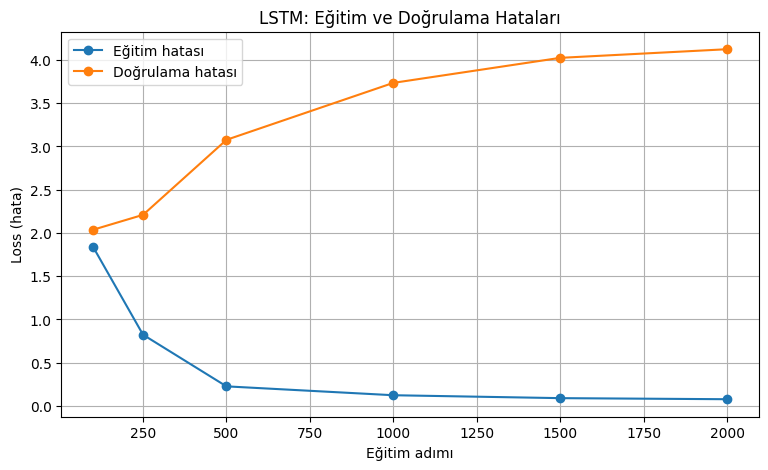

In [13]:
#Hata değerlerini karşılaştırma
import matplotlib.pyplot as plt

steps = [item["step"] for item in wide_history]
train_losses = [item["train_loss"] for item in wide_history]
val_losses = [item["val_loss"] for item in wide_history]

plt.figure(figsize=(9, 5))
plt.plot(steps, train_losses, marker="o", label="Eğitim hatası")
plt.plot(steps, val_losses, marker="o", label="Doğrulama hatası")
plt.xlabel("Eğitim adımı")
plt.ylabel("Loss (hata)")
plt.title("LSTM: Eğitim ve Doğrulama Hataları")
plt.legend()
plt.grid(True)
plt.show()


> 💡 **Grafik Ne Anlatıyor? (Overfitting - Aşırı Öğrenme)**
Grafikte mavi çizgi (Eğitim Hatası) sıfıra doğru inerken, turuncu çizginin (Doğrulama Hatası) belirli bir noktadan sonra yükselişe geçtiğini görüyoruz. Bu durum, modelimizin verinin mantığını öğrenmeyi bırakıp **metni kelimesi kelimesine ezberlemeye başladığının** en net kanıtıdır. LLM eğitimlerindeki en büyük zorluklardan biri bu makası (genelleme farkı) dar tutmaktır.

## Bağımsız Test

Son olarak, eğitim metninde bulunmayan yeni bir paragraf kullanacağız. Bu metnin karakterlerini sözlüğe eklemek, yalnızca hangi karakterlerin temsil edilebileceğini belirler; paragrafın kendisini eğitim verisine eklemeyeceğiz.

Böylece modelin daha önce görmediği bir karakter dizisindeki tahmin başarısını inceleyebileceğiz.

In [14]:
#Yeni metinle test et
wide_test_text = """
Bilim insanları yeni sorulara cevap bulmak için gözlem yapar,
deneyler tasarlar ve elde ettikleri sonuçları dikkatle inceler.
Bir bilgisayar modeli de farklı örnekler üzerinde denenmelidir.
çünkü eğitim sırasında başarılı görünen bir sistem, yeni
koşullarda beklenenden daha fazla hata yapabilir.
"""

# Sözlükte olmayan karakterleri kontrol et.
wide_unknown = sorted(set(wide_test_text) - set(wide_stoi))

print("Testte sözlükte olmayan karakterler:", wide_unknown)

if wide_unknown:
    print(
        "Bu testte sözlük dışı karakter var. "
        "Önce sözlüğü genişletip modeli yeniden eğitmek gerekir."
    )
else:
    wide_test_data = torch.tensor(
        [wide_stoi[c] for c in wide_test_text],
        dtype=torch.long,
        device=device
    )

    wide_model.eval()

    with torch.no_grad():
        test_logits, _ = wide_model(
            wide_test_data[:-1].unsqueeze(0)
        )

        wide_test_loss = wide_loss_fn(
            test_logits.reshape(-1, len(wide_chars)),
            wide_test_data[1:]
        )

    print("Bağımsız test hatası:", round(wide_test_loss.item(), 3))
    print("\nModelin ürettiği metin:\n")
    print(wide_generate(start="Bilim insanları ", length=250))


Testte sözlükte olmayan karakterler: []
Bağımsız test hatası: 3.275

Modelin ürettiği metin:

Bilim insanları yansatabilir.

Bilgisayar programlamayı öğrenirken de benzer bir süreç işler.
Önce bir problemin ne istediği anlaşılır. Ardından çözüm
küçük adımlara ayrılır ve bu adımlar bir programlamayı öğrenirken de benzer bir süreç işler.
Önce bir problemin ne 


> 💡 **Sonuçların Yorumu: Model Neden Tekrara Düştü?**
Gördüğünüz gibi modelimiz kendi eğitim verisinde harika sonuçlar (Hata: ~0.078) verirken, bağımsız testte çok zorlandı (Hata: ~3.275). Metin üretirken de bir süre sonra kelime kelime aynı şeyleri tekrarlayan bir döngüye (loop) girdi.
Bu durum, modelimizin (parametre sayısının ve eğitim verisinin küçüklüğünden dolayı) dili **genelleştiremediğini**, sadece ezberlediğini gösterir. Günümüzdeki GPT, Llama gibi devasa Büyük Dil Modelleri (LLM), milyarlarca parametre ve devasa veri setleri sayesinde işte tam olarak bu **"genelleme yeteneğini"** kazanarak tekrara düşmekten kurtulurlar.

### Karakterleri Sayısal Temsillere Dönüştürme

Sinir ağları metinleri doğrudan işleyemez; bu nedenle metindeki her benzersiz karaktere bir indeks atanır. Bu işlem, karakter tabanlı dil modelinin metin verisini sayısal bir biçimde temsil etmesini sağlar.

Bu adımda:

- **Karakter sözlüğü (`wide_stoi`):** Her karakterin karşılık geldiği sayısal indeksi gösterir.
- **Benzersiz karakter sayısı:** Modelin sözlüğünde kaç farklı karakter bulunduğunu belirtir.
- **Örnek metnin sayısallaştırılması:** `LSTM` metnindeki her karakterin indeks karşılığı gösterilir.

**Amaç:** Metnin modele verilmeden önce nasıl sayısal verilere dönüştürüldüğünü gözlemlemek.

In [15]:
# 1. Sözlükteki tüm benzersiz karakterleri ve indekslerini göster
print("Benzersiz karakter sayısı:", len(wide_chars))
print("\nKarakter → İndeks")
print("-" * 30)

for karakter, indeks in wide_stoi.items():
    print(f"{repr(karakter):8} → {indeks}")

# 2. Örnek bir metnin sayısal karşılıklarını göster
ornek = "LSTM"

sayisal_karsilik = [wide_stoi[c] for c in ornek]

print("\nÖrnek metin:", ornek)
print("Sayısal karşılıkları:", sayisal_karsilik)

Benzersiz karakter sayısı: 50

Karakter → İndeks
------------------------------
'\n'     → 0
' '      → 1
','      → 2
'.'      → 3
'A'      → 4
'B'      → 5
'D'      → 6
'G'      → 7
'H'      → 8
'K'      → 9
'L'      → 10
'M'      → 11
'P'      → 12
'S'      → 13
'T'      → 14
'V'      → 15
'Y'      → 16
'Z'      → 17
'a'      → 18
'b'      → 19
'c'      → 20
'd'      → 21
'e'      → 22
'f'      → 23
'g'      → 24
'h'      → 25
'i'      → 26
'j'      → 27
'k'      → 28
'l'      → 29
'm'      → 30
'n'      → 31
'o'      → 32
'p'      → 33
'r'      → 34
's'      → 35
't'      → 36
'u'      → 37
'v'      → 38
'y'      → 39
'z'      → 40
'Ö'      → 41
'â'      → 42
'ç'      → 43
'ö'      → 44
'ü'      → 45
'ğ'      → 46
'İ'      → 47
'ı'      → 48
'ş'      → 49

Örnek metin: LSTM
Sayısal karşılıkları: [10, 13, 14, 11]


### Sonraki Karakter Tahmini ve Olasılık Dağılımı

Eğitilmiş LSTM modeli, kendisine verilen karakter dizisini işleyerek sıradaki karakter için tahmin üretir.

- **Girdi:** Modelin devamını tahmin etmesi istenen başlangıç metni.
- **Logits:** Modelin her olası karakter için ürettiği ham skorlar.
- **Softmax:** Ham skorları toplamı 1 olan olasılıklara dönüştürür.
- **Top-k:** Olasılığı en yüksek 10 karakteri ve olasılıklarını listeler.

**Amaç:** Modelin tek bir karakteri doğrudan belirlemek yerine, olası karakterler üzerinde bir olasılık dağılımı oluşturduğunu gözlemlemek.

In [16]:

import torch

baslangic = "Yapay zekâ "

# Başlangıç metninin tüm karakterleri sözlükte olmalı.
assert all(c in wide_stoi for c in baslangic), \
    "Başlangıç metninde sözlükte olmayan karakter var."

x = torch.tensor(
    [[wide_stoi[c] for c in baslangic]],
    dtype=torch.long,
    device=device
)

wide_model.eval()

with torch.no_grad():
    logits, state = wide_model(x)

    # Son konumdaki tahminleri olasılığa dönüştür.
    olasiliklar = torch.softmax(logits[0, -1, :], dim=-1)

    # En yüksek olasılıklı 10 karakteri bul.
    degerler, indeksler = torch.topk(
        olasiliklar,
        k=min(10, len(wide_chars))
    )

print("Girdi:", repr(baslangic))
print("\nSonraki karakter tahminleri:")

for indeks, olasilik in zip(indeksler, degerler):
    karakter = wide_itos[indeks.item()]
    print(f"{karakter!r:8} → %{olasilik.item() * 100:.2f}")


Girdi: 'Yapay zekâ '

Sonraki karakter tahminleri:
's'      → %99.20
'v'      → %0.71
'y'      → %0.03
'b'      → %0.02
'k'      → %0.01
't'      → %0.01
'g'      → %0.01
'ı'      → %0.00
','      → %0.00
'd'      → %0.00


### Sonraki karakterlerin olasılık grafiği

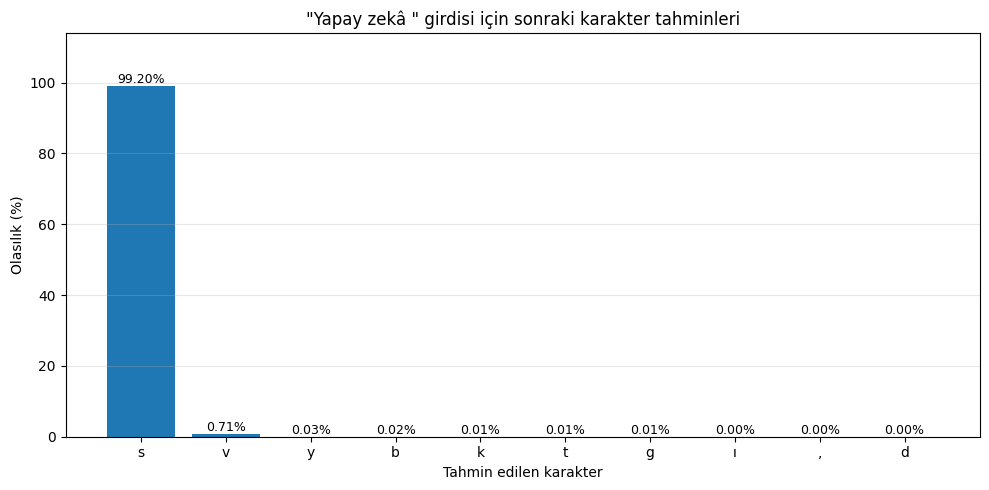

In [17]:

import torch
import matplotlib.pyplot as plt

baslangic = "Yapay zekâ "

x = torch.tensor(
    [[wide_stoi[c] for c in baslangic]],
    dtype=torch.long,
    device=device
)

wide_model.eval()

with torch.no_grad():
    logits, _ = wide_model(x)
    olasiliklar = torch.softmax(logits[0, -1, :], dim=-1)
    degerler, indeksler = torch.topk(
        olasiliklar,
        k=min(10, len(wide_chars))
    )

karakterler = [wide_itos[i.item()] for i in indeksler]
yuzdeler = [p.item() * 100 for p in degerler]

plt.figure(figsize=(10, 5))
bars = plt.bar(karakterler, yuzdeler)

plt.xlabel("Tahmin edilen karakter")
plt.ylabel("Olasılık (%)")
plt.title(f'"{baslangic}" girdisi için sonraki karakter tahminleri')

for bar, yuzde in zip(bars, yuzdeler):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{yuzde:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.ylim(0, max(yuzdeler) * 1.15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Eğitim ve doğrulama hataları arasındaki fark

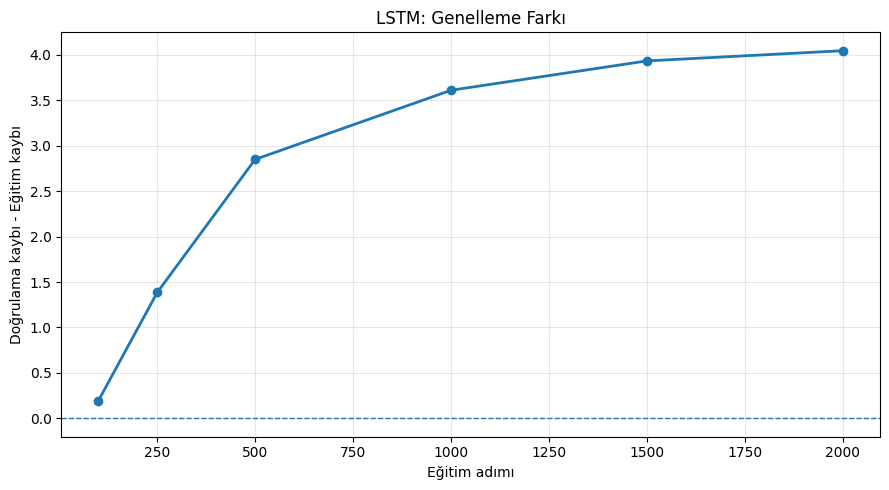

In [18]:

import matplotlib.pyplot as plt

steps = [item["step"] for item in wide_history]
train_losses = [item["train_loss"] for item in wide_history]
val_losses = [item["val_loss"] for item in wide_history]

gap = [
    val - train
    for train, val in zip(train_losses, val_losses)
]

plt.figure(figsize=(9, 5))
plt.plot(steps, gap, marker="o", linewidth=2)

plt.axhline(0, linestyle="--", linewidth=1)
plt.xlabel("Eğitim adımı")
plt.ylabel("Doğrulama kaybı - Eğitim kaybı")
plt.title("LSTM: Genelleme Farkı")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


> 💡 **Genelleme Farkı (Generalization Gap) Ne Anlatıyor?**
> İdeal bir makine öğrenmesi eğitiminde bu farkın sıfıra yakın ve yatay seyretmesini bekleriz. Ancak grafikte çizginin **sürekli yukarı doğru tırmanması**, modelin eğitim metnini ezberledikçe (overfitting), daha önce hiç görmediği metinlere karşı tahmin yeteneğinin giderek bozulduğunu gösteriyor.
> Bu tırmanış, neden devasa LLM'lerde Dropout, Ağırlık Azaltımı (Weight Decay) gibi düzenlileştirme tekniklerine ve çok daha büyük/çeşitli veri setlerine ihtiyaç duyduğumuzun görsel bir ispatıdır.